# Day 1: Getting the Data & First Look

Alright, day one of the RetailPulse project! The goal today is simple: get our hands on some data and just get a feel for it. 

Since we don't have a real client database hooked up yet, I'm going to generate a realistic synthetic dataset. I want to make sure it has the right characteristics for our later tasks—like seasonal spikes for our forecasting models, and a few messy missing values so we have something to clean on Day 2. 

Let's build the data generator first, then we'll dive straight into the Exploratory Data Analysis (EDA).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from faker import Faker
import os
from datetime import datetime
import warnings

# I always suppress warnings in EDA notebooks to keep the output clean
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Create a folder for our raw data
os.makedirs('data', exist_ok=True)
fake = Faker()
np.random.seed(42) # For reproducibility

print("Generating synthetic retail data...")

# --- 1. Customers ---
num_customers = 2000 
customers = pd.DataFrame({
    'customer_id': [f'CUST_{i:05d}' for i in range(1, num_customers + 1)],
    'age': np.random.randint(18, 75, num_customers),
    'join_date': [fake.date_between(start_date='-3y', end_date='-1m') for _ in range(num_customers)],
    'region': np.random.choice(['North', 'South', 'East', 'West'], num_customers)
})

# --- 2. Products ---
categories = ['Electronics', 'Clothing', 'Groceries', 'Home']
products = pd.DataFrame({
    'product_id': [f'PROD_{i:04d}' for i in range(1, 101)],
    'category': np.random.choice(categories, 100),
    'unit_price': np.random.uniform(5.0, 500.0, 100).round(2)
})

# --- 3. Transactions (The big one) ---
start_date = datetime(2025, 1, 1)
end_date = datetime(2026, 6, 25) 
date_range = pd.date_range(start=start_date, end=end_date, freq='D')

transactions = []
for date in date_range:
    # Injecting seasonality: more sales in Nov/Dec and on weekends
    month_factor = 1.6 if date.month in [11, 12] else 1.0
    weekend_factor = 1.3 if date.weekday() >= 5 else 1.0
    
    daily_tx_count = int(np.random.poisson(100 * month_factor * weekend_factor))
    
    for _ in range(daily_tx_count):
        prod = products.sample(1).iloc[0]
        qty = np.random.choice([1, 2, 3], p=[0.7, 0.2, 0.1])
        
        # Injecting ~2% missing values in payment_method to test our cleaning skills later
        payment = np.random.choice(['Credit Card', 'Debit Card', 'Cash', np.nan], 
                                   p=[0.4, 0.3, 0.28, 0.02])
        
        transactions.append({
            'transaction_id': f'TXN_{len(transactions)+1:07d}',
            'date': date,
            'customer_id': np.random.choice(customers['customer_id']),
            'product_id': prod['product_id'],
            'quantity': qty,
            'total_amount': round(qty * prod['unit_price'], 2),
            'payment_method': payment
        })

transactions_df = pd.DataFrame(transactions)

# Save them to CSVs
customers.to_csv('data/customers_raw.csv', index=False)
products.to_csv('data/products_raw.csv', index=False)
transactions_df.to_csv('data/transactions_raw.csv', index=False)

print(f"✅ Data generated! Created {len(customers)} customers, {len(products)} products, and {len(transactions_df)} transactions.")

Generating synthetic retail data...
✅ Data generated! Created 2000 customers, 100 products, and 62611 transactions.


### Loading the Data
Okay, the data is saved to our `data/` folder. Now let's actually load it up and see what we're working with. I'm mostly interested in the transactions table since that's where the money is.

In [4]:
# Load the data
customers = pd.read_csv('data/customers_raw.csv', parse_dates=['join_date'])
products = pd.read_csv('data/products_raw.csv')
transactions = pd.read_csv('data/transactions_raw.csv', parse_dates=['date'])

print("Shapes:")
print(f"Customers:    {customers.shape}")
print(f"Products:     {products.shape}")
print(f"Transactions: {transactions.shape}")

print("\nFirst 5 transactions:")
display(transactions.head())

Shapes:
Customers:    (2000, 4)
Products:     (100, 3)
Transactions: (62611, 7)

First 5 transactions:


,transaction_id,date,customer_id,product_id,quantity,total_amount,payment_method
0,TXN_0000001,2025-01-01,CUST_01629,PROD_0050,1,96.74,Cash
1,TXN_0000002,2025-01-01,CUST_01573,PROD_0071,1,161.89,Cash
2,TXN_0000003,2025-01-01,CUST_00337,PROD_0064,1,455.27,Credit Card
3,TXN_0000004,2025-01-01,CUST_01257,PROD_0078,1,317.50,Credit Card
4,TXN_0000005,2025-01-01,CUST_01809,PROD_0064,3,1365.81,Cash


### Checking for Missing Values
First order of business: checking for nulls. In the real world, data is never perfect. I purposely injected a few missing `payment_method` values in the generator, so let's visualize exactly how messy things are.

Missing values per column in Transactions:
transaction_id       0
date                 0
customer_id          0
product_id           0
quantity             0
total_amount         0
payment_method    1237
dtype: int64


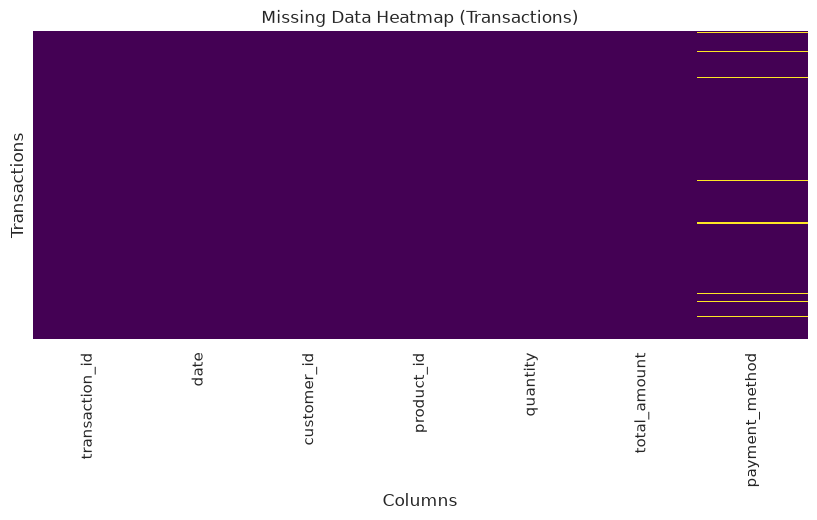

In [5]:
# Let's check the exact counts first
print("Missing values per column in Transactions:")
print(transactions.isnull().sum())

# A heatmap is a great way to visually spot missing data patterns
plt.figure(figsize=(10, 4))
sns.heatmap(transactions.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Data Heatmap (Transactions)')
plt.xlabel('Columns')
plt.ylabel('Transactions')
plt.show()

Looks like `payment_method` has a few gaps, but the rest of the transaction data is solid. We'll handle those nulls tomorrow.

### Distribution Analysis
Now let's look at the shape of our data. Are sales normally distributed? (Spoiler: almost never in retail). Let's plot the transaction amounts and customer ages to get a feel for the distributions.

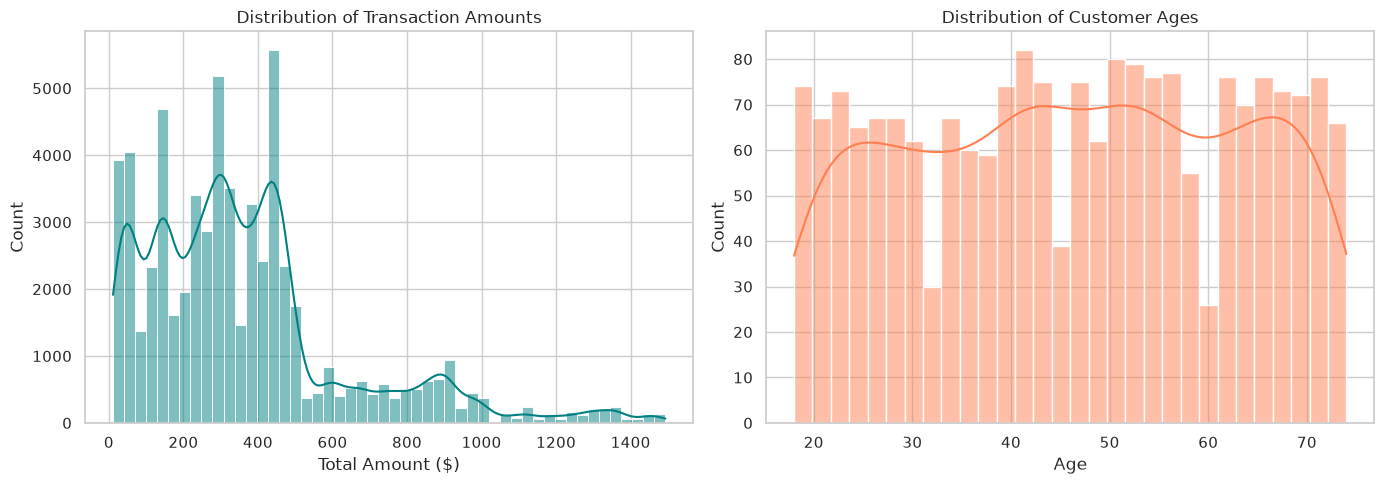

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Transaction Amounts
sns.histplot(transactions['total_amount'], bins=50, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribution of Transaction Amounts')
axes[0].set_xlabel('Total Amount ($)')

# Customer Ages
sns.histplot(customers['age'], bins=30, kde=True, color='coral', ax=axes[1])
axes[1].set_title('Distribution of Customer Ages')
axes[1].set_xlabel('Age')

plt.tight_layout()
plt.show()

Notice how the transaction amount plot is heavily right-skewed? That's totally normal. Most people buy cheap stuff, but a few people buy expensive electronics, creating a long tail. We might need to apply a log transformation later when we train our models.

### Time-Series Overview
Since a huge part of this project is demand forecasting, we need to look at the time dimension. Let's aggregate the daily sales and plot it. I want to see if our seasonality (holiday spikes) actually made it into the data.

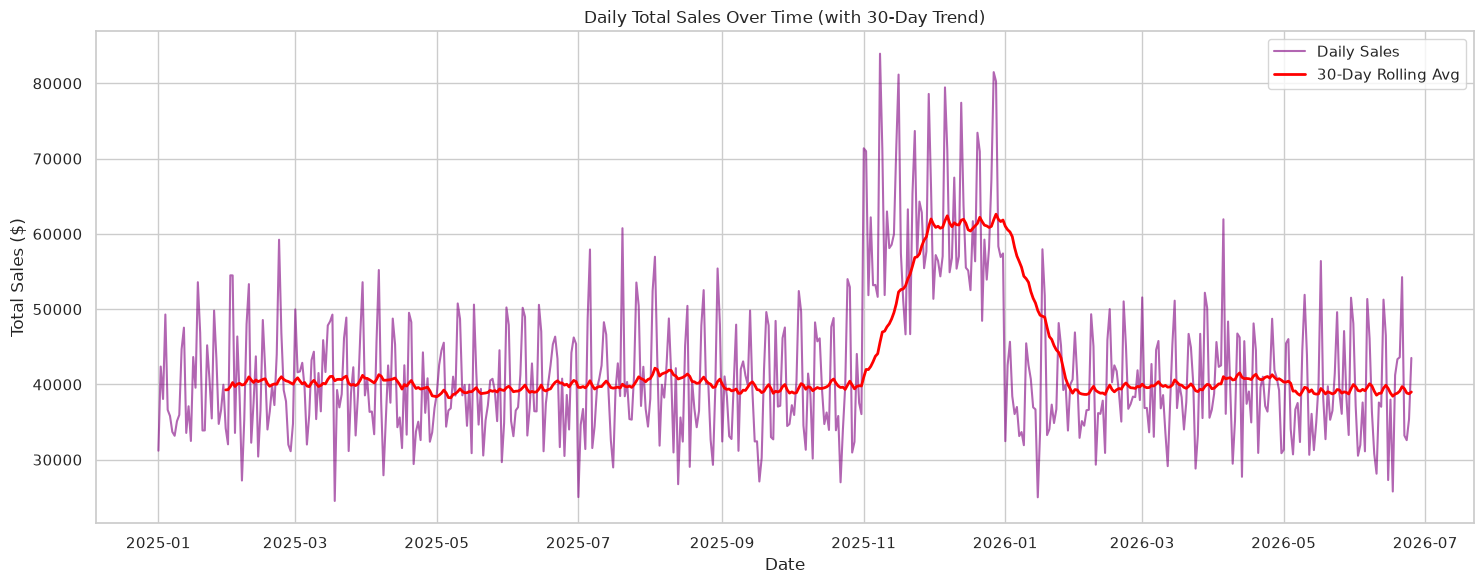

In [8]:
# Group by date and sum the total sales
daily_sales = transactions.groupby('date')['total_amount'].sum().reset_index()

plt.figure(figsize=(15, 6))
plt.plot(daily_sales['date'], daily_sales['total_amount'], color='purple', alpha=0.6, label='Daily Sales')

# Let's also add a 30-day rolling average to smooth out the daily noise and see the trend
daily_sales['rolling_30d'] = daily_sales['total_amount'].rolling(window=30).mean()
plt.plot(daily_sales['date'], daily_sales['rolling_30d'], color='red', linewidth=2, label='30-Day Rolling Avg')

plt.title('Daily Total Sales Over Time (with 30-Day Trend)')
plt.xlabel('Date')
plt.ylabel('Total Sales ($)')
plt.legend()
plt.tight_layout()
plt.show()

Perfect. You can clearly see the massive spikes in Nov/Dec (the red line shoots up), and the general upward trend over the 1.5 years. This is going to be a great dataset for testing our Prophet and LSTM models.

### Correlation Matrix
Finally, let's see how our numerical features relate to each other. Does buying a higher quantity always mean a proportionally higher total amount? Let's check.

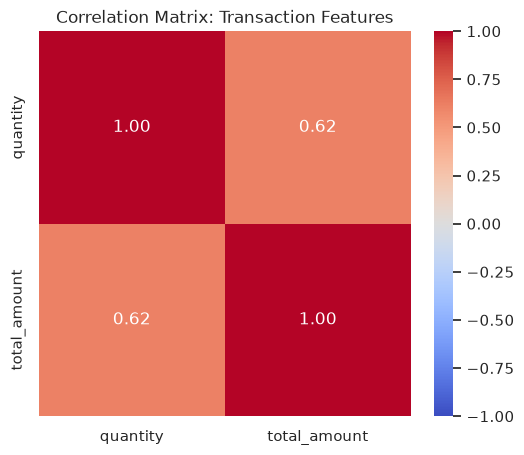

In [9]:
# We only have two purely numerical columns in transactions: quantity and total_amount
corr_matrix = transactions[['quantity', 'total_amount']].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title('Correlation Matrix: Transaction Features')
plt.show()

### Wrap Up
That's a wrap for Day 1! 

**What we accomplished:**
- Generated a realistic, messy synthetic retail dataset.
- Checked for missing values (found some in `payment_method`).
- Analyzed distributions (found right-skewed sales).
- Verified time-series seasonality (holiday spikes are present).
- Checked basic correlations.

Tomorrow (Day 2), we'll clean up those missing values, engineer some RFM features for our customers, and set up Great Expectations to make sure our data pipeline doesn't break in production.